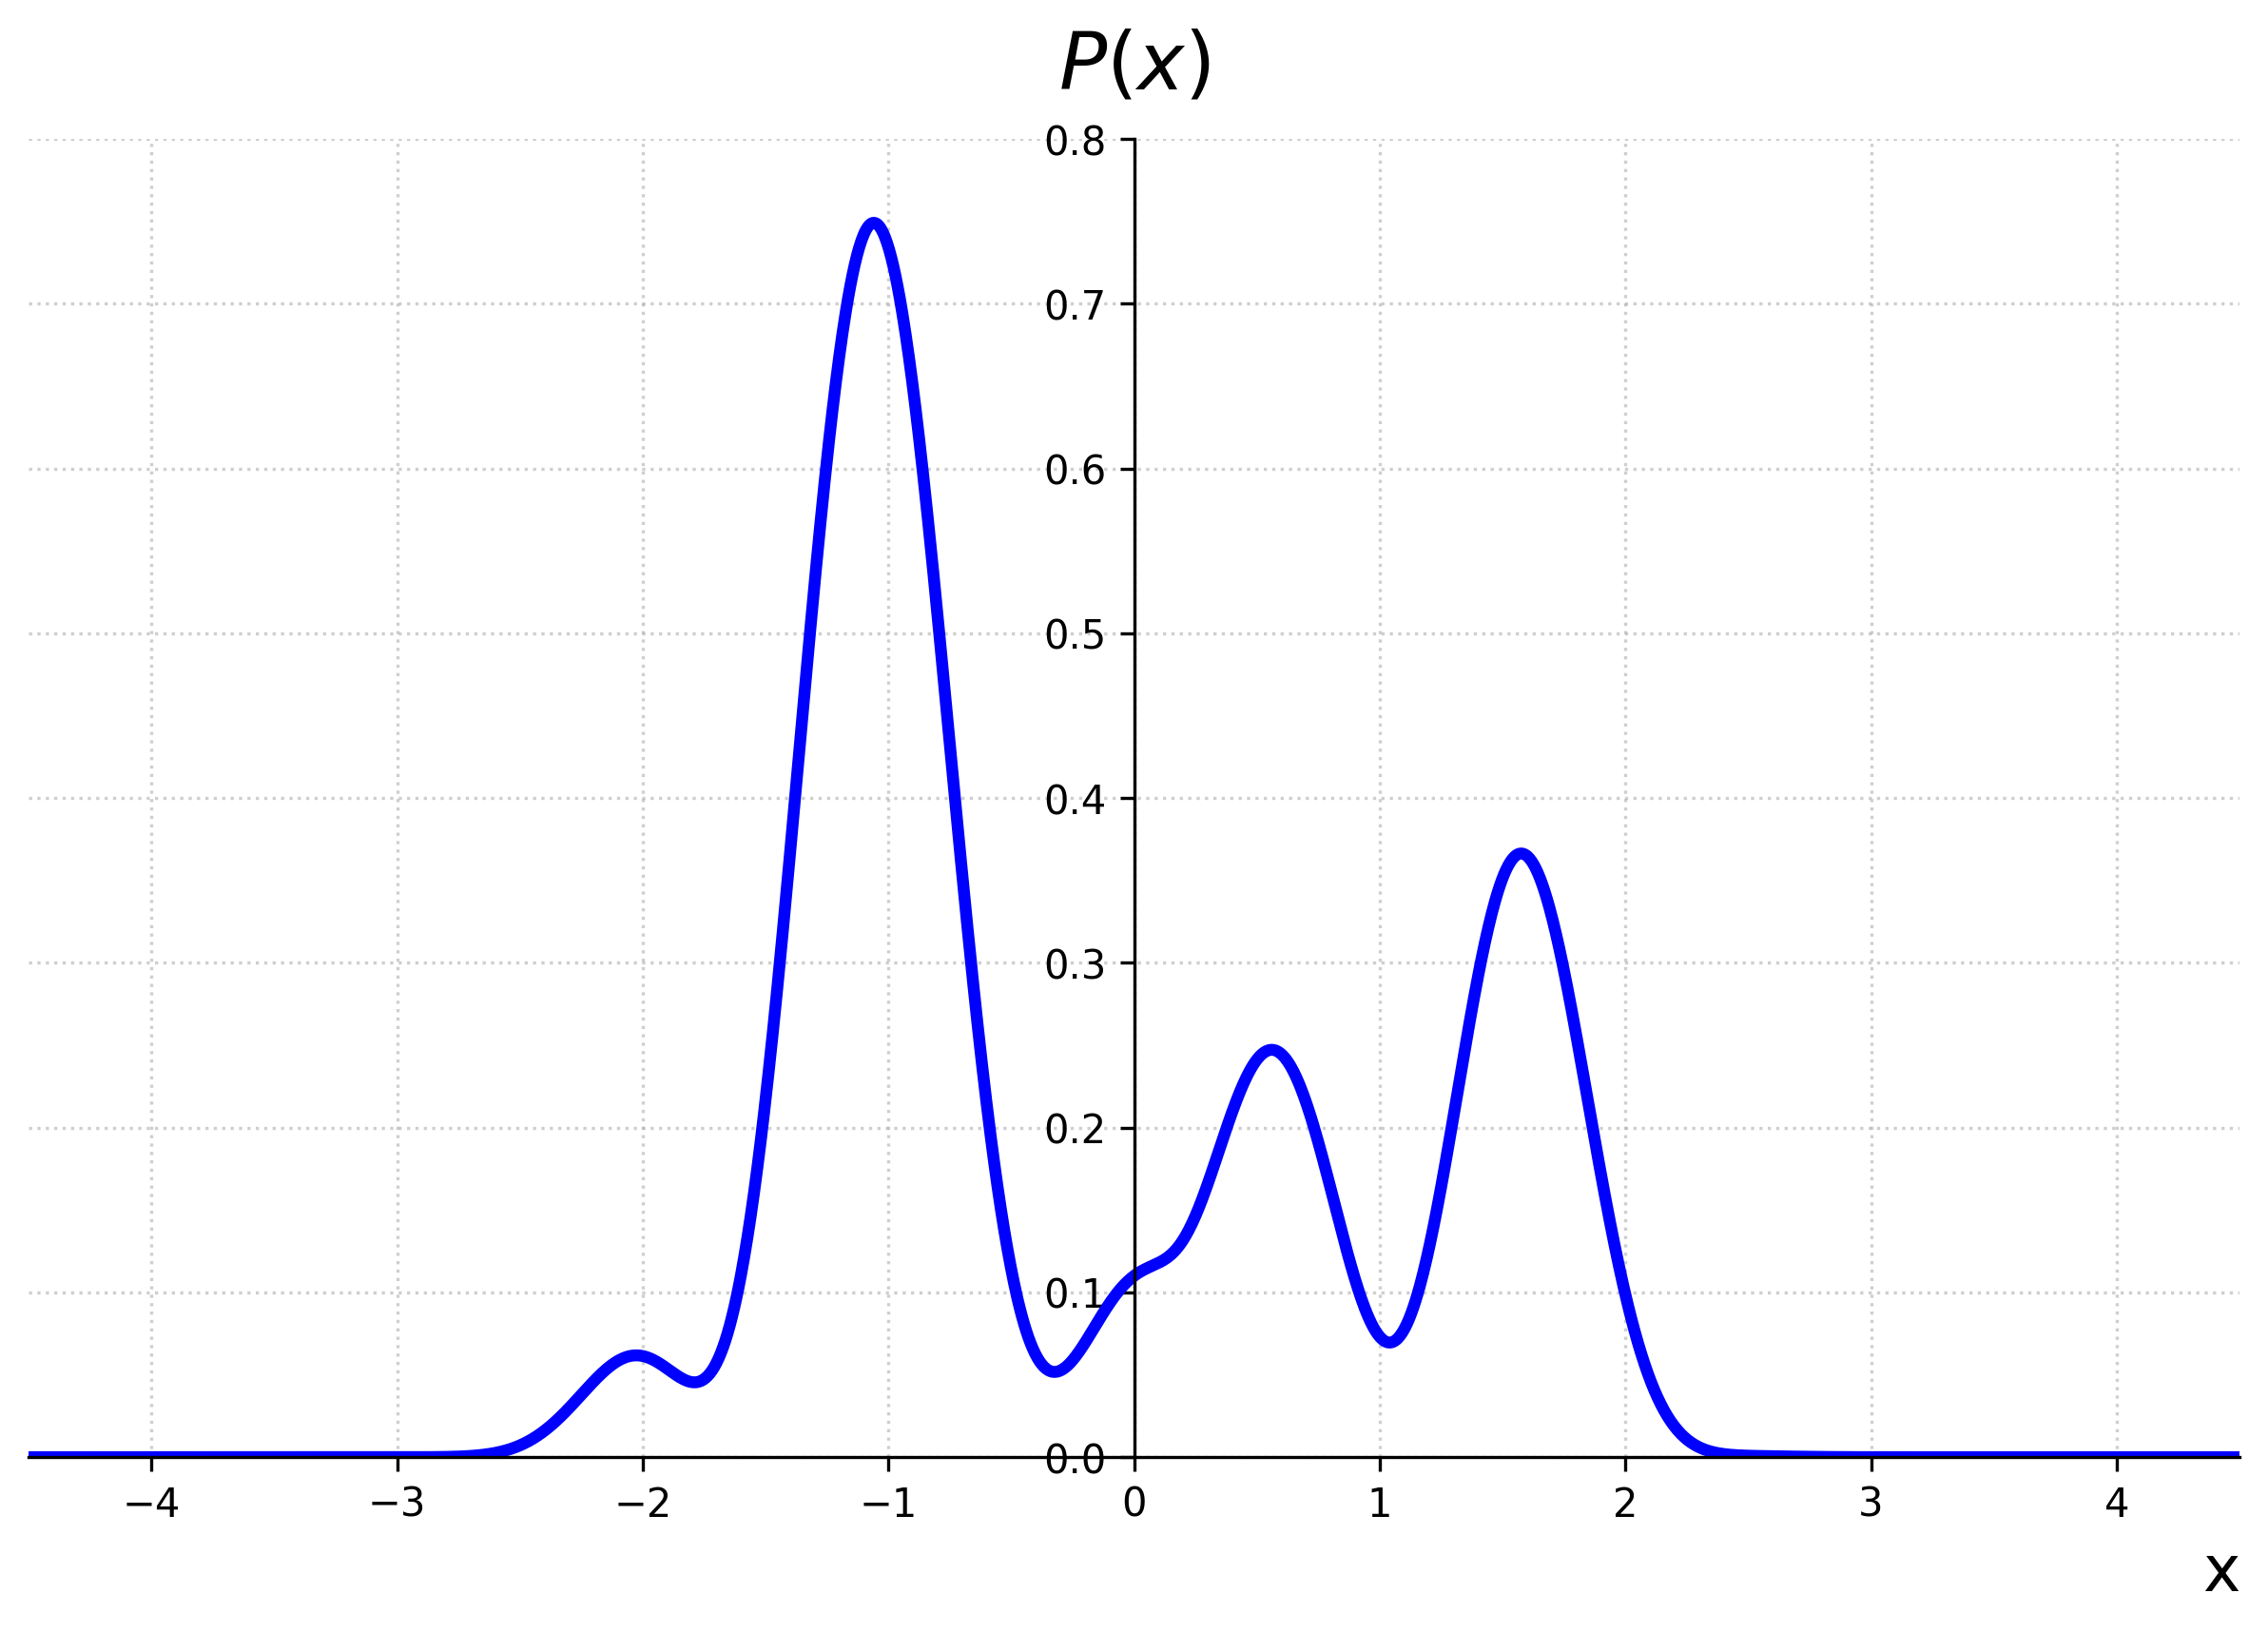

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Configuración de datos
# Creamos un rango de x suave con 2000 puntos para que la curva se vea perfecta
x = np.linspace(-4.5, 4.5, 2000)

# 2. La Ecuación Exacta (Ec. 5 del Paper)
# Constante de normalización dada en el texto
A = 0.028202 

# Desglosamos la ecuación por términos para claridad
term1 = np.sqrt(5 + (2 - 11*x)**2)
term2 = 1.3 + np.sin(4.5 * x)  # 13/10 = 1.3, 9/2 = 4.5
term3 = np.exp(-(x**4)/7)

P = A * term1 * term2 * term3

# 3. Creación del Gráfico
plt.figure(figsize=(10, 6), dpi=300) # dpi=300 asegura alta calidad para impresión

# Graficamos
plt.plot(x, P, color='blue', linewidth=3, label='P(x)')

# 4. Estilo "Académico" (Ejes centrados)
ax = plt.gca()

# Ocultamos los bordes superior y derecho
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')

# Movemos los ejes izquierdo e inferior al cero (0,0)
ax.spines['left'].set_position(('data', 0))
ax.spines['bottom'].set_position(('data', 0))

# Ajustes de Ticks y Etiquetas
plt.xlim(-4.5, 4.5)
plt.ylim(0, 0.8)
plt.title(r'$P(x)$', fontsize=20, y=1.02) # Título usando LaTeX
plt.xlabel('x', fontsize=16, loc='right')

# Cuadrícula suave (opcional, ayuda a leer)
plt.grid(True, linestyle=':', alpha=0.6)

# Guardar la imagen
plt.savefig("grafico_alta_calidad.png", transparent=True, bbox_inches='tight')
plt.show()

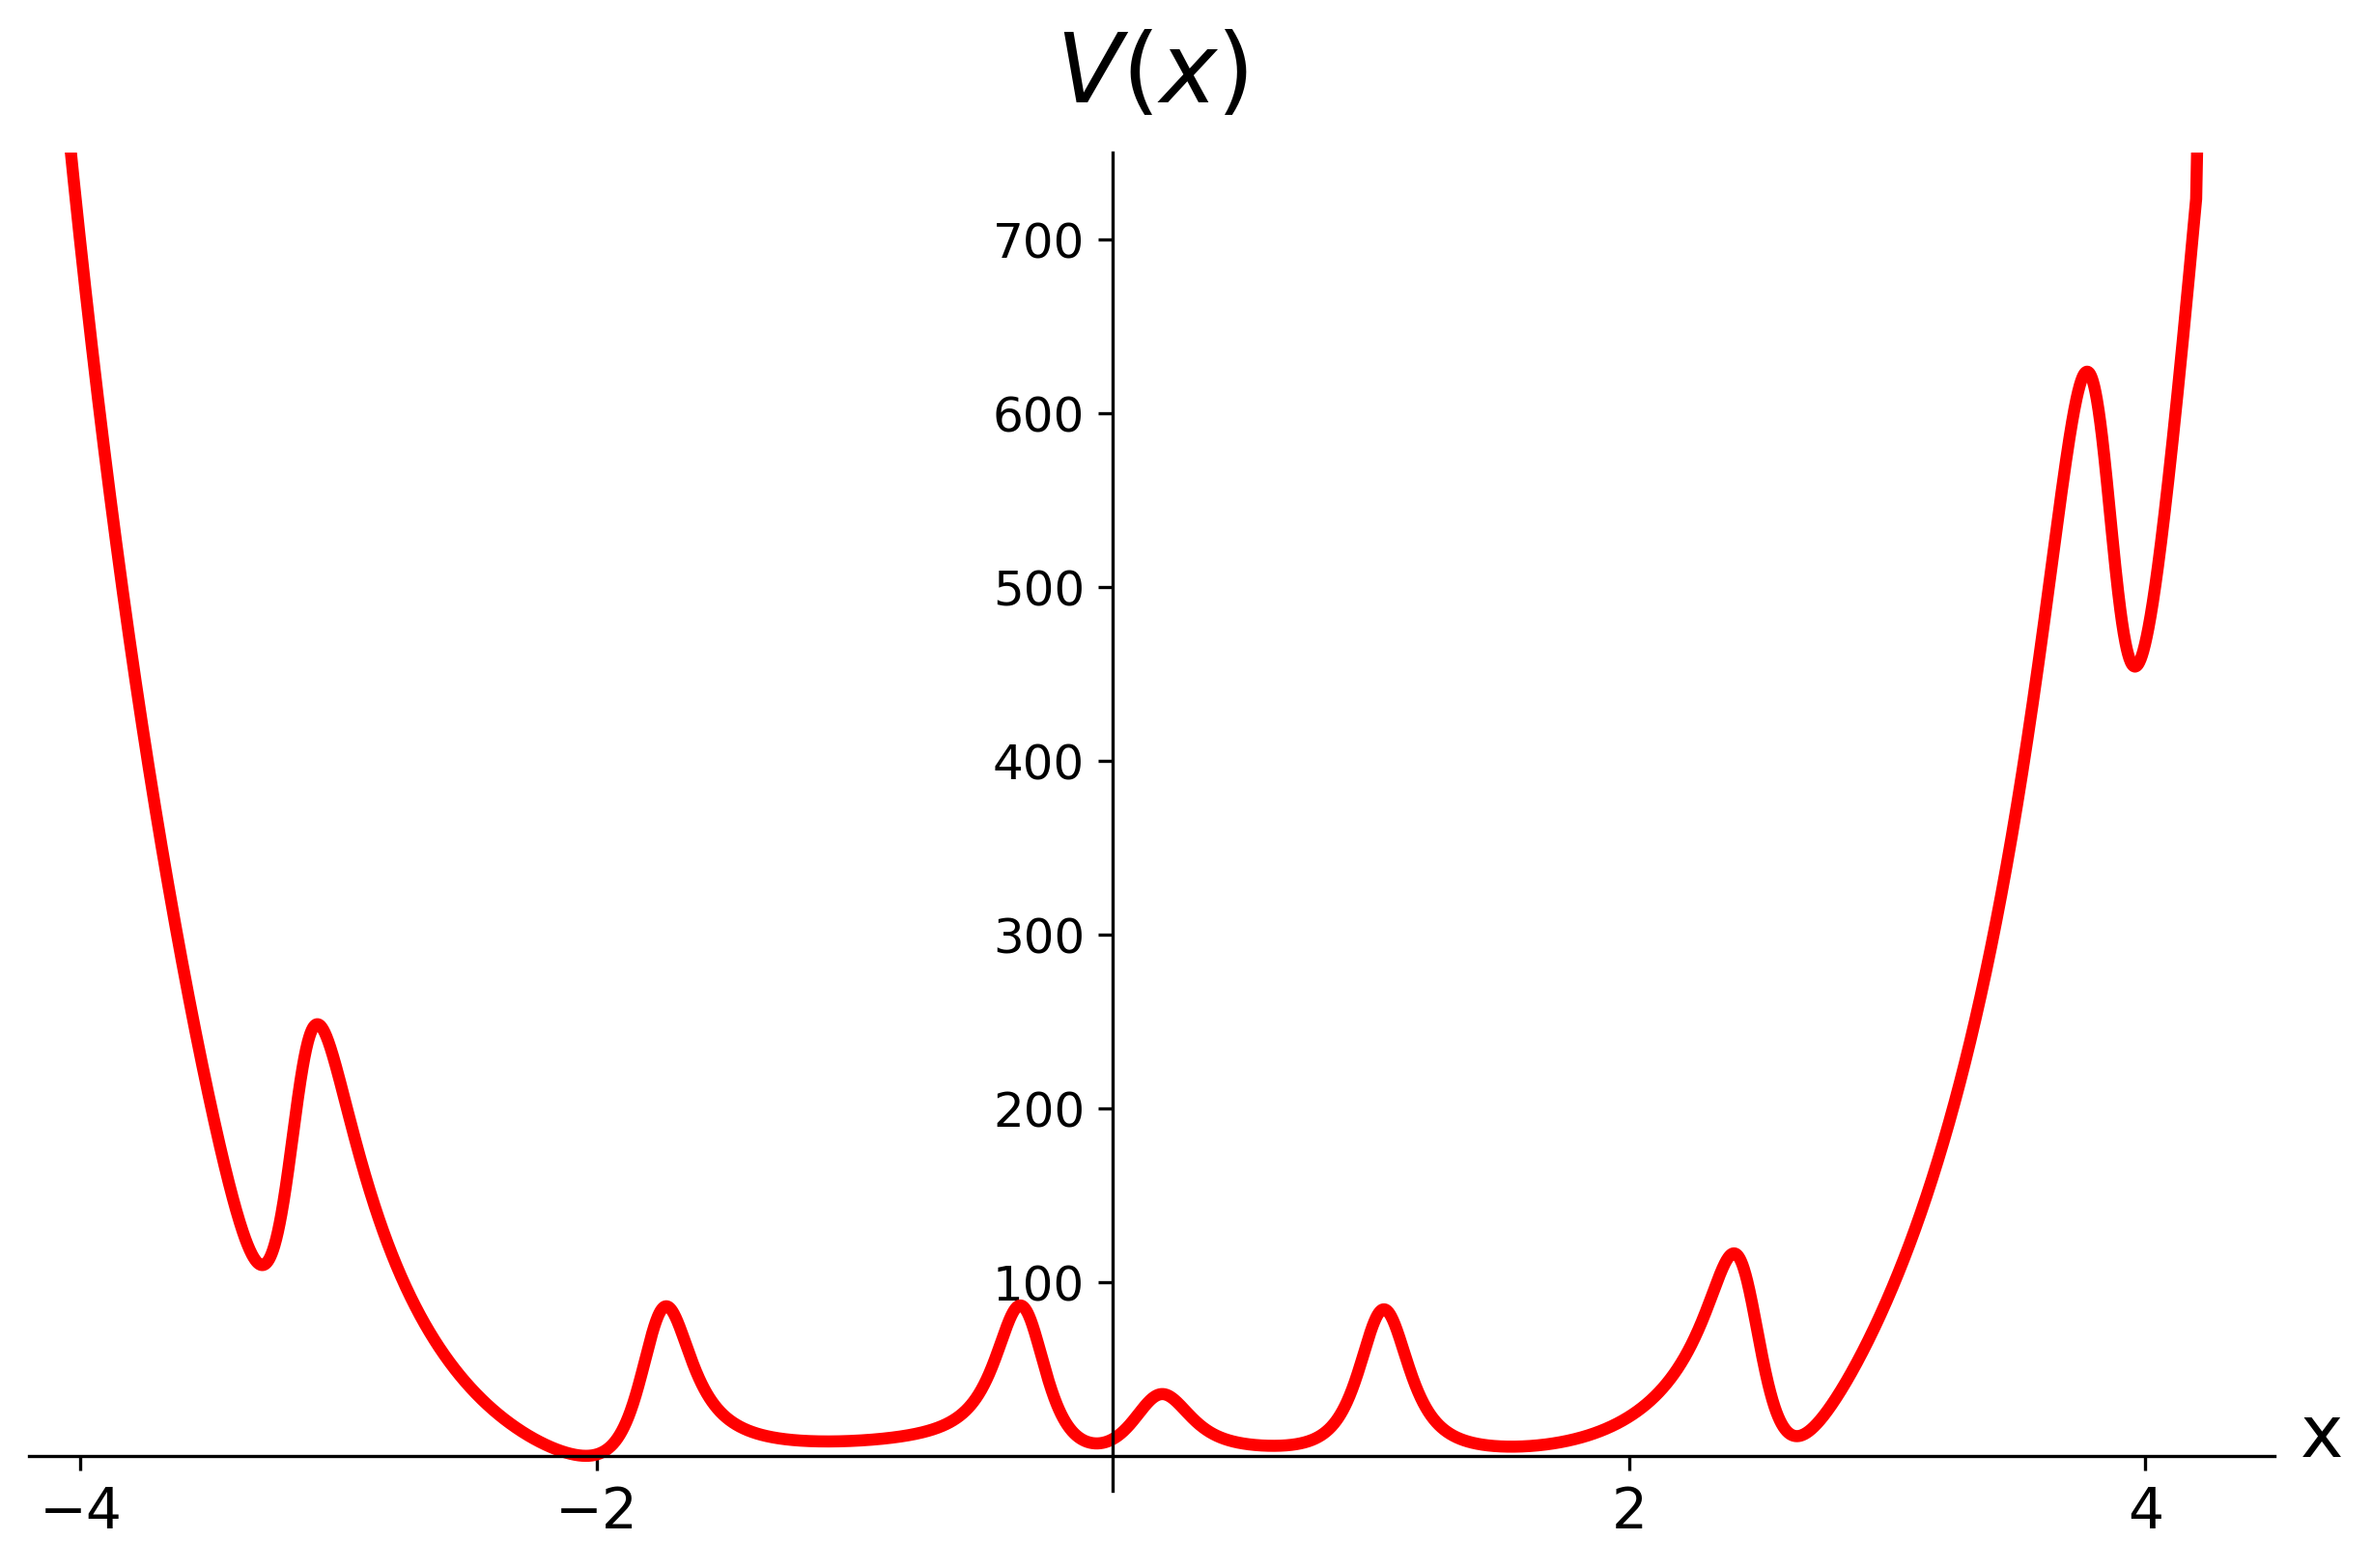

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Configuración del Dominio
# Usamos un rango denso para capturar bien los picos finos
x = np.linspace(-4.2, 4.2, 5000)
dx = x[1] - x[0] # Paso diferencial para calcular derivadas

# 2. Definición de P(x) (La misma ecuación del gráfico anterior)
# Nota: La constante 'A' de normalización NO afecta la forma del potencial V(x),
# ya que al derivar el logaritmo de una constante, se vuelve cero.
term1 = np.sqrt(5 + (2 - 11*x)**2)
term2 = 1.3 + np.sin(4.5 * x)
term3 = np.exp(-(x**4)/7)

P = term1 * term2 * term3

# 3. Cálculo de f(x) y el Potencial V(x)
# f(x) = -ln(P(x))
f = -np.log(P)

# Derivadas Numéricas (usando gradiente de numpy para precisión)
df = np.gradient(f, dx)      # Primera derivada (df/dx)
d2f = np.gradient(df, dx)    # Segunda derivada (d^2f/dx^2)

# Ecuación Maestra Inversa (Ec. 4 del paper)
# Asumiendo h_bar^2 / 4m = 1 como indica el paper en la Fig 1b
V = -d2f + 0.5 * (df**2)

# Ajuste fino: En el paper, el mínimo local parece tocar casi el cero.
# Restamos el mínimo para alinear la gráfica visualmente con la referencia.
V_shifted = V - np.min(V)

# 4. Creación del Gráfico Estilo Paper
plt.figure(figsize=(10, 6), dpi=300)

# Graficamos la curva roja
plt.plot(x, V_shifted, color='red', linewidth=3, label='V(x)')

# 5. Estética de los Ejes
ax = plt.gca()

# Ocultar bordes superior y derecho
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')

# Posicionar ejes
ax.spines['left'].set_position(('data', 0)) # Eje Y en x=0
ax.spines['bottom'].set_position(('data', 0)) # Eje X en y=0

# Límites y Ticks (Coincidiendo con Fig 1b)
plt.xlim(-4.2, 4.5)
plt.ylim(-20, 750) # Un poco de margen abajo y hasta 700 arriba
plt.xticks([-4, -2, 2, 4], fontsize=14)
plt.yticks(np.arange(100, 800, 100), fontsize=12)

# Título
plt.title(r'$V(x)$', fontsize=24, y=1.02)
plt.text(4.6, 0, 'x', fontsize=18) # Etiqueta x manual al final del eje

# Guardar
plt.savefig("potencial_inverso_alta_calidad.png", transparent=True, bbox_inches='tight')
plt.show()

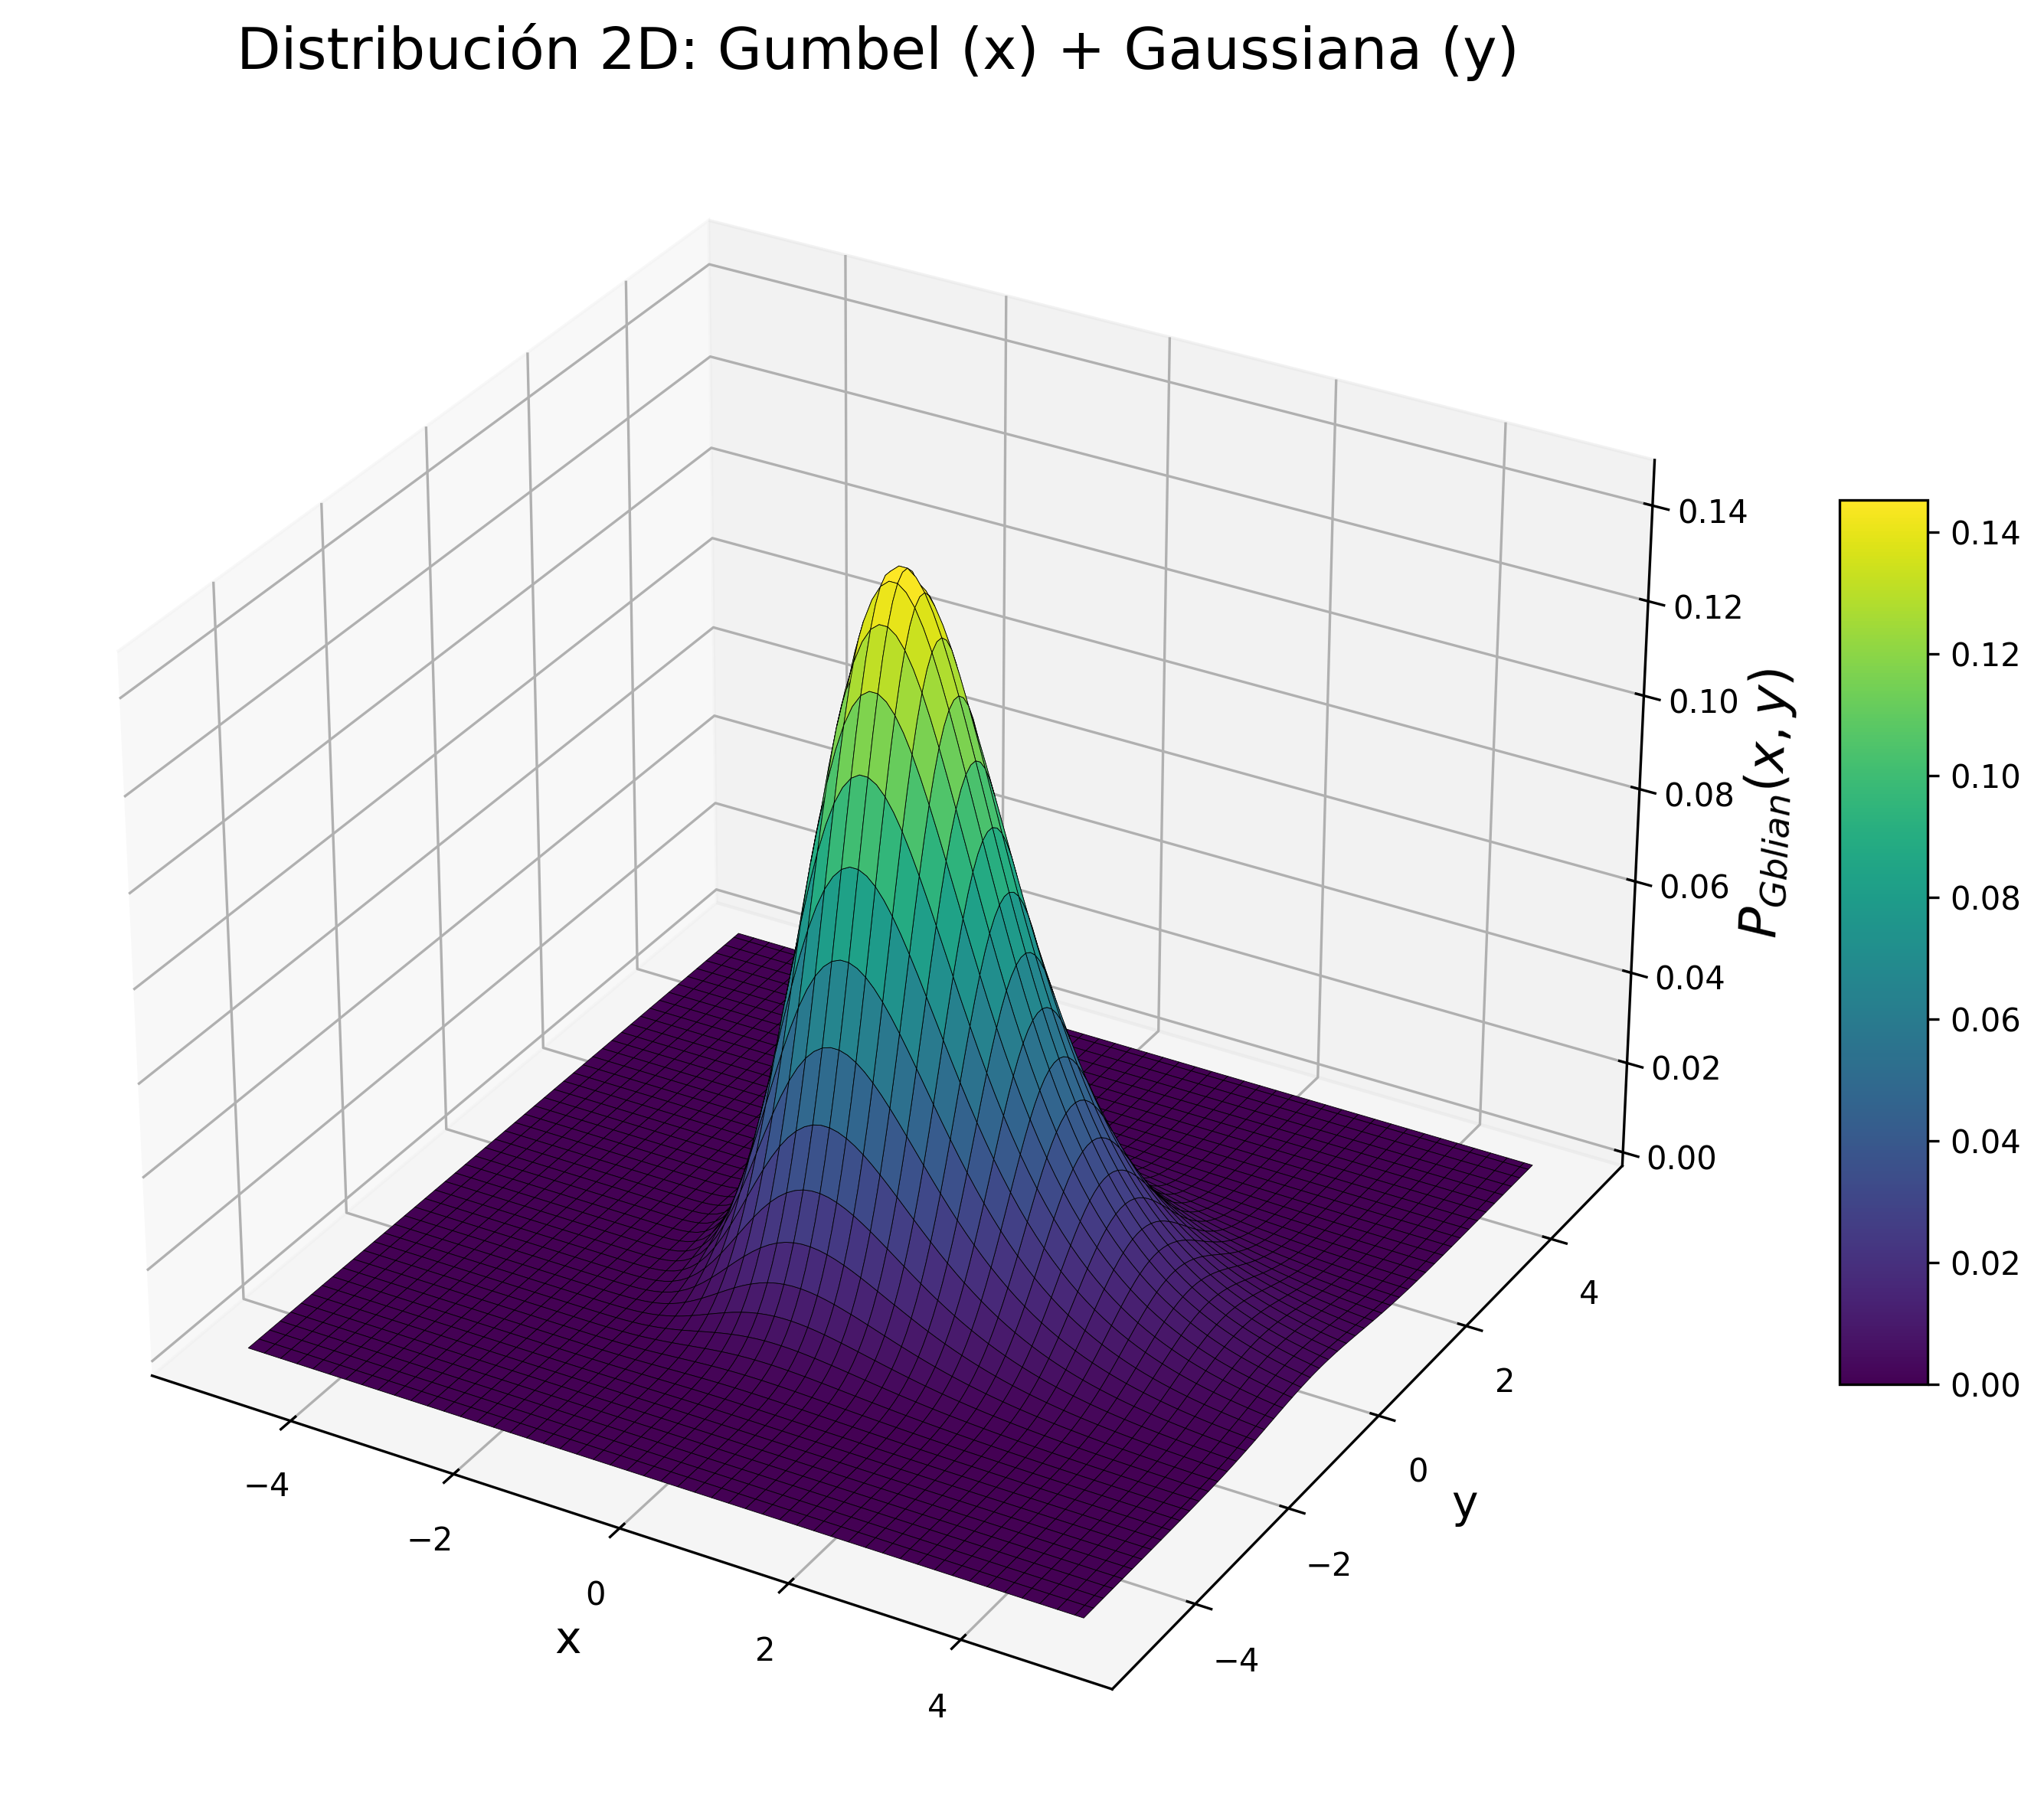

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Configuración de la Malla (Grid) 2D
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x, y)

# 2. Parámetros del Paper (Pág. 5, Fig 2)
beta = 1.0   # Escala Gumbel
sigma = 1.0  # Escala Gaussiana
x0 = 0       # Centro X
y0 = 0       # Centro Y

# 3. Definición de las Probabilidades
# Eje Y: Gaussiana (Simétrica)
P_gauss = (1 / (np.sqrt(2 * np.pi) * sigma)) * np.exp(-((Y - y0)**2) / (2 * sigma**2))

# Eje X: Gumbel (Asimétrica - La fórmula exacta de la Ec. 6)
z_gumbel = (X - x0) / beta
P_gumbel = (1 / beta) * np.exp(-(z_gumbel + np.exp(-z_gumbel)))

# Probabilidad Total 2D (Multiplicación por ser separable)
P_total = P_gumbel * P_gauss

# 4. Creación del Gráfico 3D
fig = plt.figure(figsize=(12, 10), dpi=300)
ax = fig.add_subplot(111, projection='3d')

# Plot de superficie
surf = ax.plot_surface(X, Y, P_total, cmap='viridis', edgecolor='k', linewidth=0.2, antialiased=True)

# 5. Estética (Igualando al Paper)
ax.set_xlabel('x', fontsize=14)
ax.set_ylabel('y', fontsize=14)
ax.set_zlabel(r'$P_{Gblian}(x,y)$', fontsize=16)
ax.set_title('Distribución 2D: Gumbel (x) + Gaussiana (y)', fontsize=18)
ax.view_init(elev=30, azim=-60) # Ángulo de cámara similar al paper

# Barra de color
fig.colorbar(surf, shrink=0.5, aspect=10)

plt.savefig("grafico_3D_Gblian.png", transparent=True, bbox_inches='tight')
plt.show()

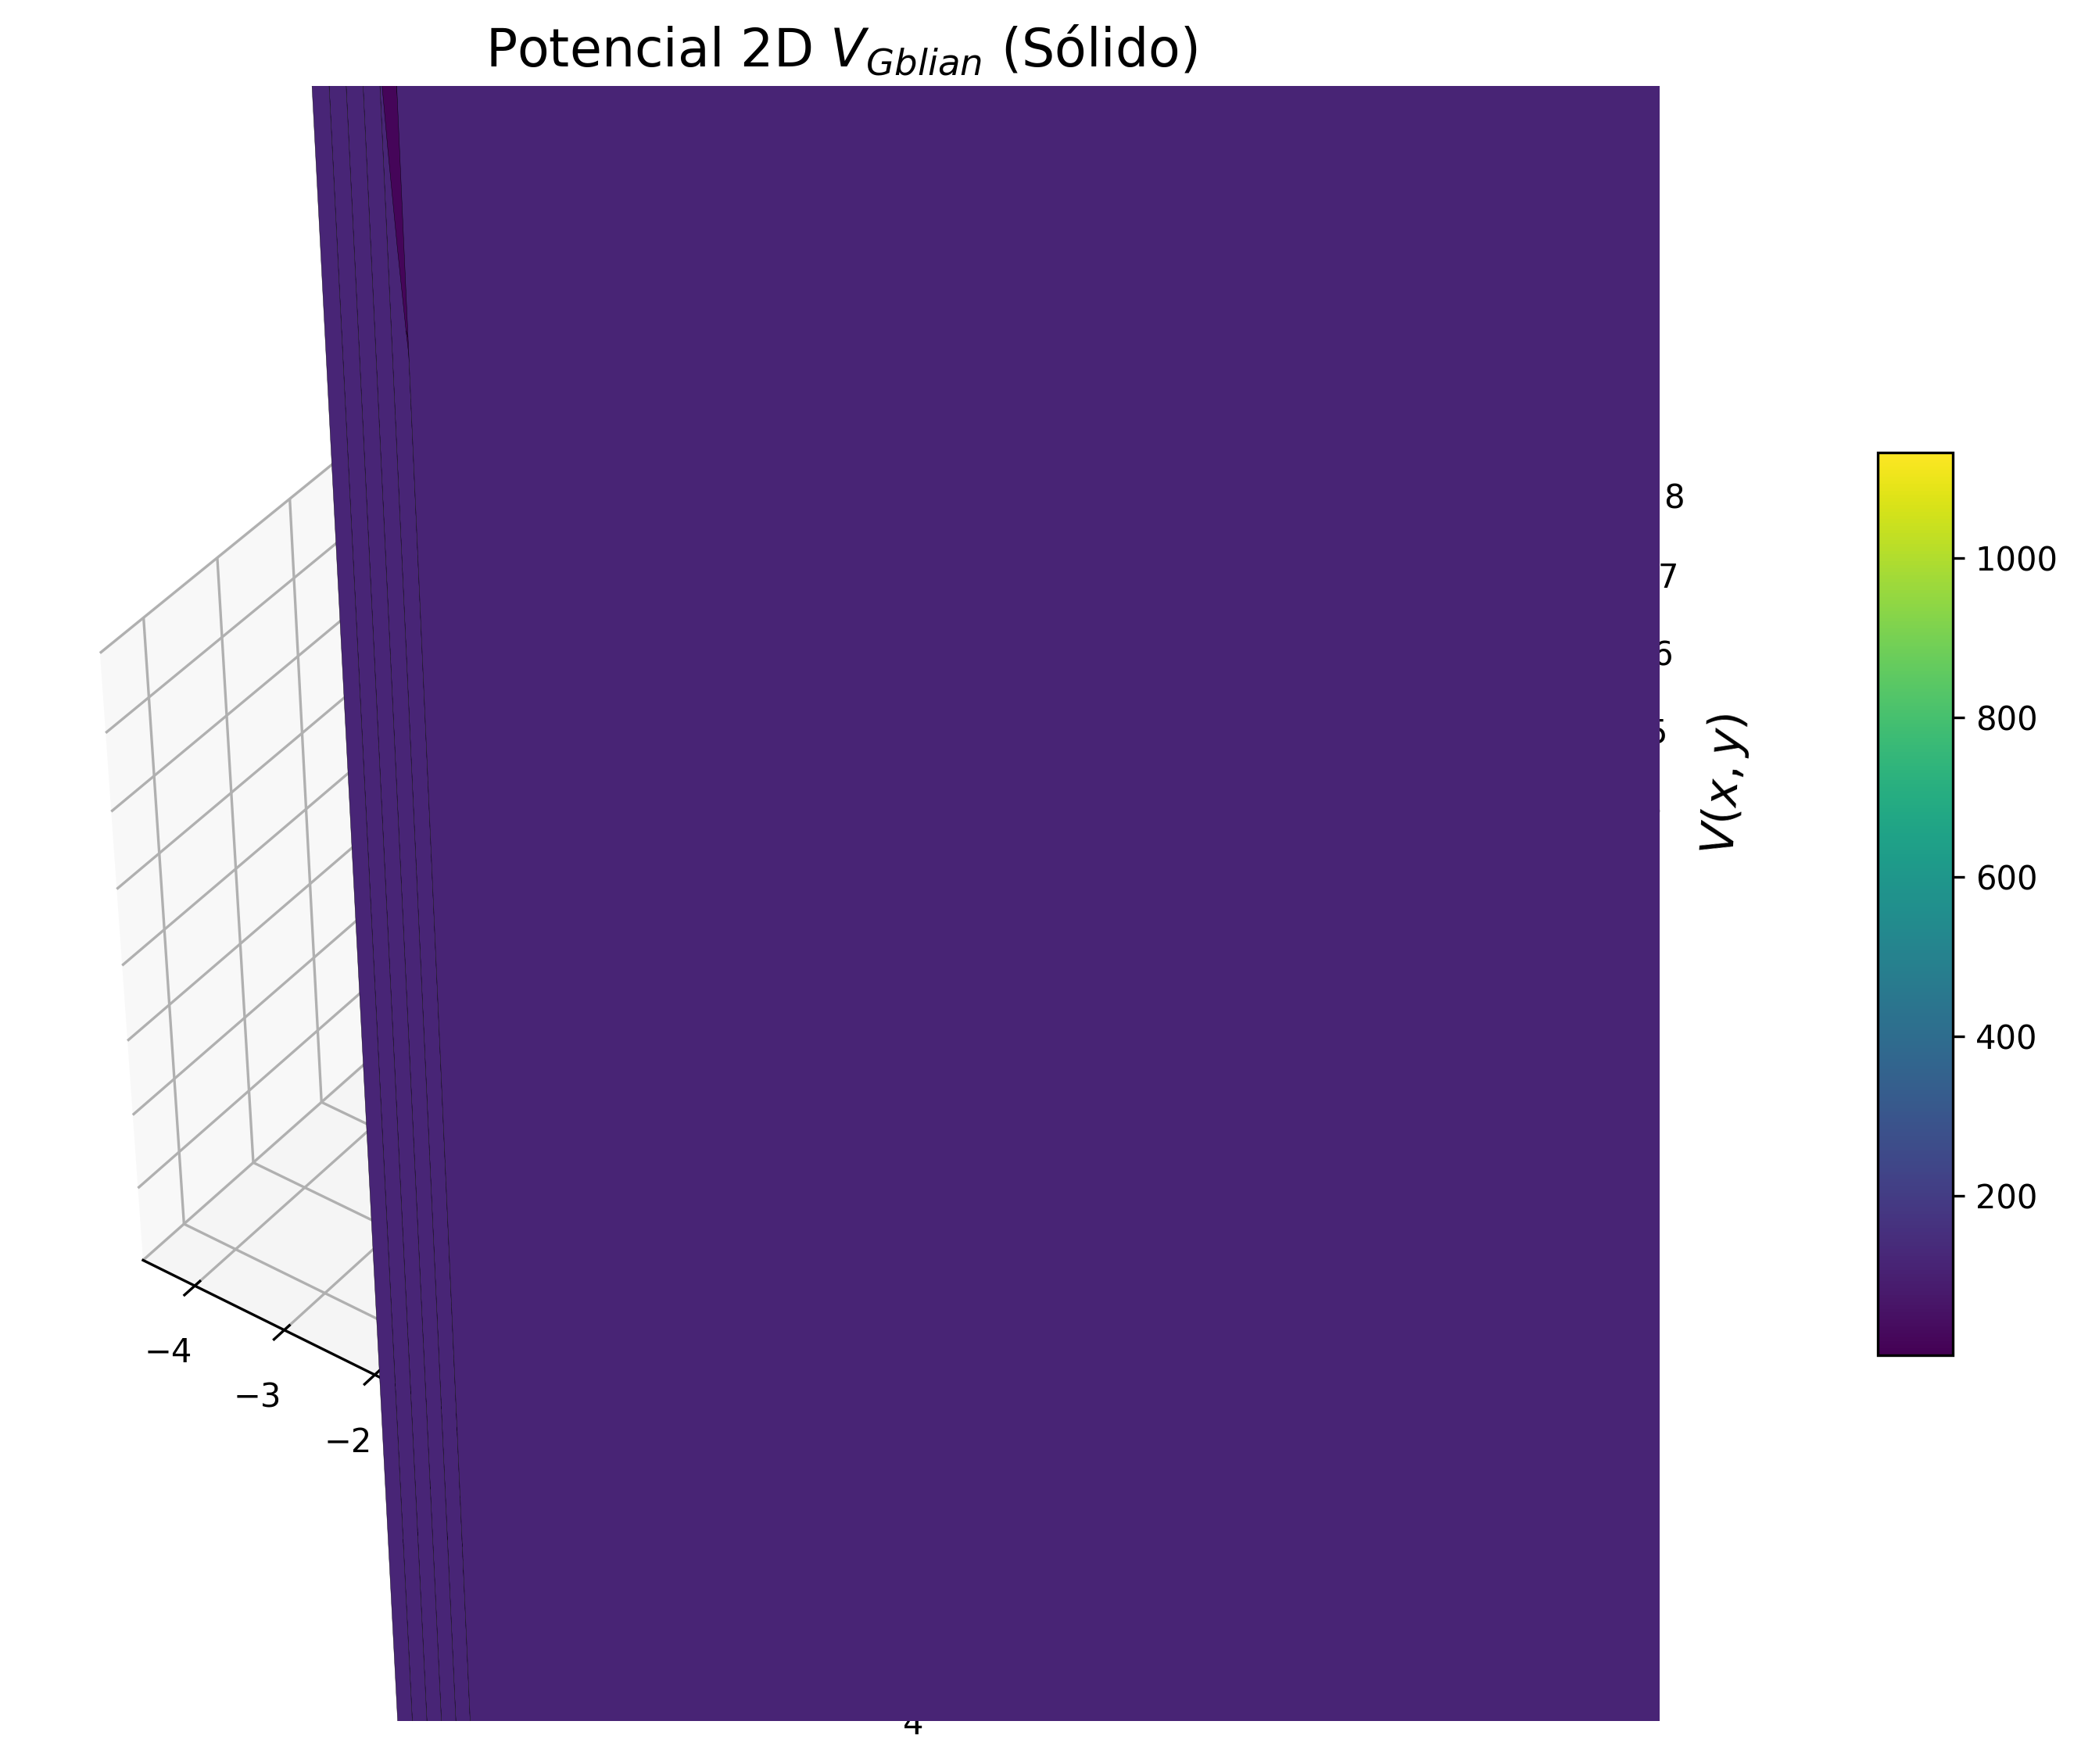

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Datos (Igual que antes)
x = np.linspace(-4, 4, 150)
y = np.linspace(-4, 4, 150)
X, Y = np.meshgrid(x, y)

# 2. Matemáticas del Potencial
# Gumbel en X (Asimétrico)
z = X 
V_x = 0.5 * np.exp(-2*z) - 2 * np.exp(-z) + 2

# Oscilador en Y (Simétrico)
V_y = 0.5 * Y**2

# Total
V_total = V_x + V_y

# 3. Gráfico Limpio
fig = plt.figure(figsize=(12, 10), dpi=300)
ax = fig.add_subplot(111, projection='3d')

# ### CAMBIO CLAVE AQUÍ ###
# alpha=1.0 (Opacidad total, elimina la "capa extra")
# linewidth=0.1 (Líneas muy finas para que no ensucien)
# rstride=4, cstride=4 (Hacemos la cuadrícula más densa pero suave)
surf = ax.plot_surface(X, Y, V_total, cmap='viridis', 
                       edgecolor='black', linewidth=0.1, 
                       rstride=4, cstride=4,
                       alpha=1.0,  # <--- ESTO ARREGLA EL PROBLEMA
                       antialiased=True,
                       shade=True) # Añade sombras para dar volumen 3D real

# 4. Límites y Estética
ax.set_zlim(0, 8) 
ax.set_xlabel('x (Gumbel)', fontsize=12)
ax.set_ylabel('y (Gauss)', fontsize=12)
ax.set_zlabel(r'$V(x,y)$', fontsize=14)
ax.set_title(r'Potencial 2D $V_{Gblian}$ (Sólido)', fontsize=16)

# Ángulo de cámara limpio
ax.view_init(elev=40, azim=-55)

# Barra de color
fig.colorbar(surf, shrink=0.5, aspect=12, pad=0.1)

plt.savefig("potencial_solido_final.png", transparent=True, bbox_inches='tight')
plt.show()

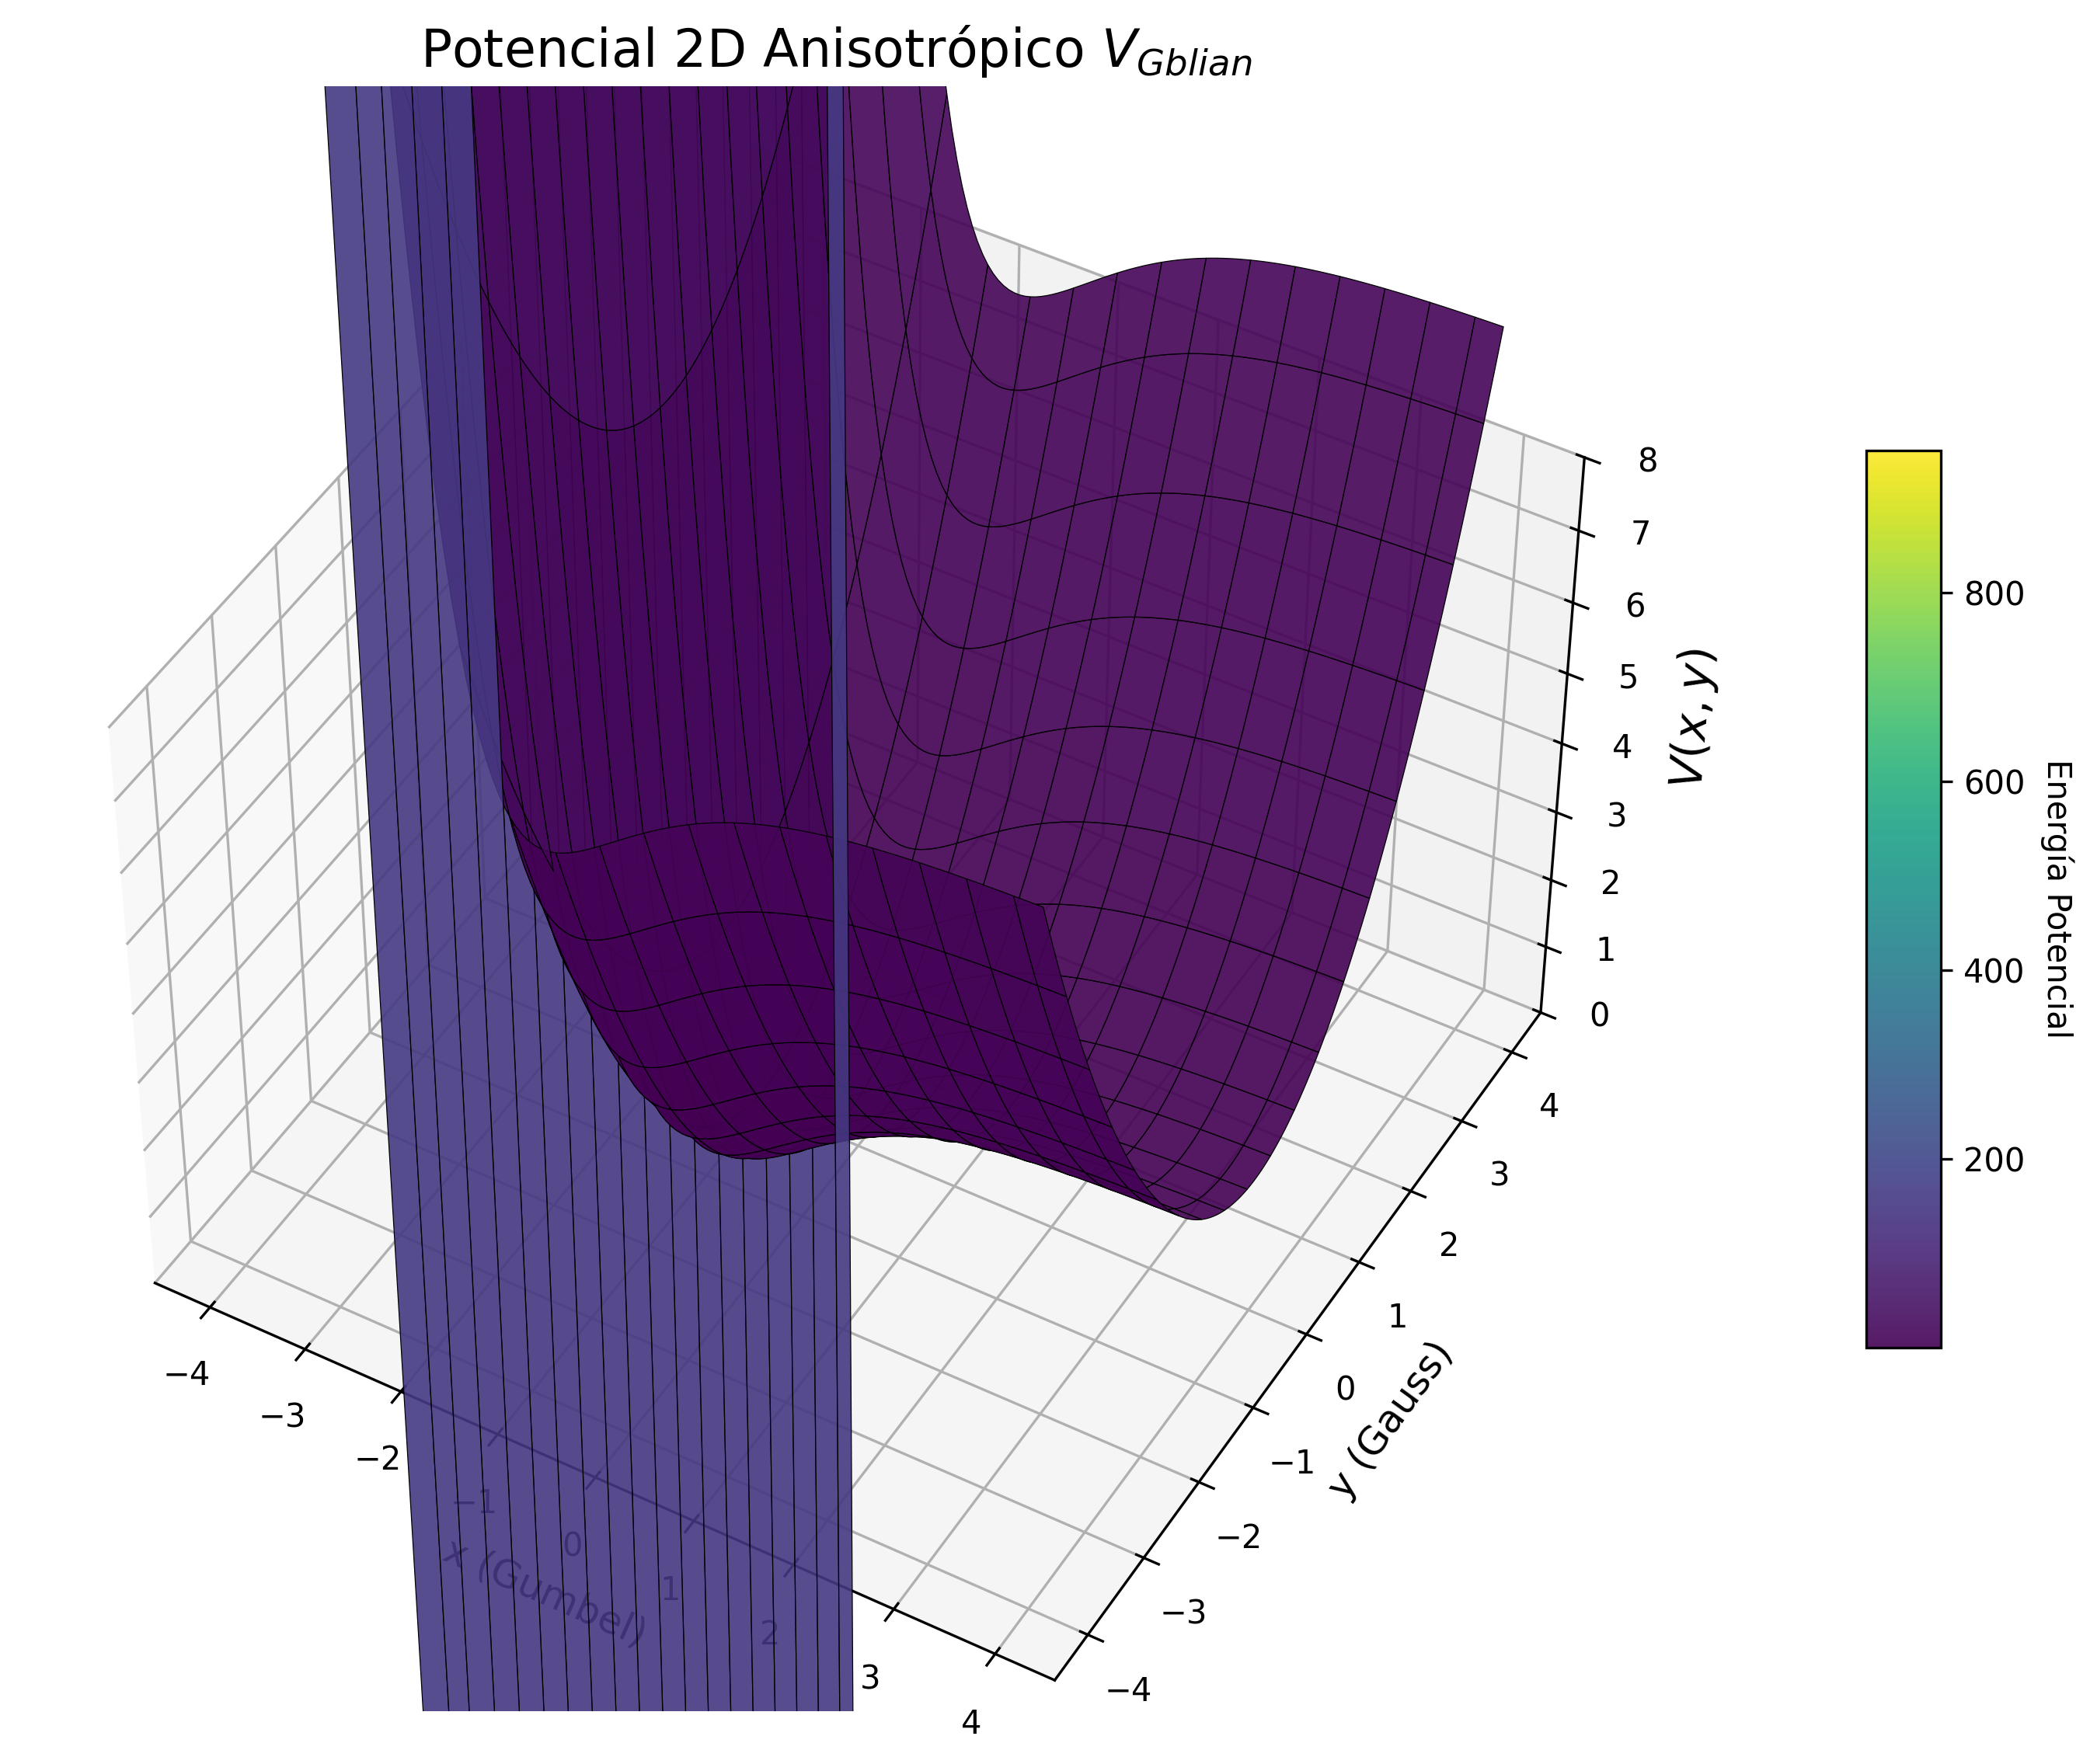

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Configuración de la Malla (Resolución)
# Usamos una malla densa para el cálculo, pero visualizaremos menos líneas después
x = np.linspace(-4, 4, 150) # Reduje un poco el rango para centrar la acción
y = np.linspace(-4, 4, 150)
X, Y = np.meshgrid(x, y)

# 2. Ecuaciones del Potencial (Separables)
# Eje X: Potencial de Gumbel (Asimétrico)
# V_x = 0.5 * e^(-2x) - 2 * e^(-x) + 2  (Derivado de Tabla I y Eq. 3)
# Esto asegura que el mínimo sea 0 y asintóticamente vaya a 2 a la derecha.
z = X  # Asumiendo beta=1, x0=0
V_x = 0.5 * np.exp(-2*z) - 2 * np.exp(-z) + 2

# Eje Y: Oscilador Armónico (Simétrico)
# V_y = 0.5 * y^2
V_y = 0.5 * Y**2

# Potencial Total
V_total = V_x + V_y

# 3. Creación del Gráfico Estético
fig = plt.figure(figsize=(12, 10), dpi=300)
ax = fig.add_subplot(111, projection='3d')

# TRUCO VISUAL: 'rstride' y 'cstride' controlan cada cuántos puntos se dibuja una línea.
# Esto evita que el gráfico se vea negro por exceso de líneas.
surf = ax.plot_surface(X, Y, V_total, cmap='viridis', 
                       edgecolor='black', linewidth=0.3, # Líneas finas y elegantes
                       rstride=8, cstride=8,             # Dibujar línea cada 8 puntos
                       alpha=0.9, antialiased=True)

# 4. Límites y Cortes (Clave para que no se vea extraño)
ax.set_zlim(0, 8) # Cortamos en 8 igual que la Fig 2b del paper

# 5. Etiquetas y Estilo
ax.set_xlabel('x (Gumbel)', fontsize=12)
ax.set_ylabel('y (Gauss)', fontsize=12)
ax.set_zlabel(r'$V(x,y)$', fontsize=14)
ax.set_title(r'Potencial 2D Anisotrópico $V_{Gblian}$', fontsize=16)

# Ángulo de cámara (Elevación y Azimut) para resaltar la forma de "Canaleta"
ax.view_init(elev=45, azim=-60)

# Barra de color discreta
cbar = fig.colorbar(surf, shrink=0.5, aspect=12, pad=0.1)
cbar.set_label('Energía Potencial', rotation=270, labelpad=15)

plt.savefig("potencial_3D_final.png", transparent=True, bbox_inches='tight')
plt.show()